In [29]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.5 * nS 
g_AMPA_rec_E = 5.5 * nS 
g_AMPA_ext_I = 5.5 * nS
g_AMPA_rec_I = 5.5 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

recurrent_radius = 2


kill_mask = np.ones(100, dtype=np.float32)
# kill_mask[np.array([range(45,47),range(35,37),range(55,57)]).flatten()]=0
# pen_idx = np.concatenate([range(24,28),[34,38,44,48,54,58],range(41,68)])
# far_idx = np.concatenate([range(1,18),range(71,99)])

# kill_mask[range(32,37)]=0 
# pen_idx = np.concatenate([range(21,28),[31,38],range(41,48)])
# far_idx = np.concatenate([range(1,18),range(71,99)])

# kill_mask[np.array([range(42,47),range(32,37)]).flatten()]=0
# pen_idx = np.concatenate([range(21,28),[31,38,41,48],range(51,58)])
# far_idx = np.concatenate([range(1,18),range(71,99)])

# kill_mask[55]=0
# core_idx = np.where(kill_mask == 0)[0]          


def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler',name='P_E')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.35  
    P_E.k_GABA_E_hsp = 0.35  
    P_E.tau_ins_AMPA_E = tau_ins_AMPA   #50'000
    P_E.tau_int_AMPA_E = tau_int_AMPA   #5'000
    P_E.tau_ins_GABA_E = tau_ins_GABA   
    P_E.tau_int_GABA_E = tau_int_GABA  

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler',name='P_I')
    P_I.v = V_L


    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    
    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)



    C_PG_E.w[:] = 1.05 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.42, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.8#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.32, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

   
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')

    r_est_mon = StateMonitor(P_E, variables=['r_est'], record=[45], name = 'r_est',dt=record_dt)

    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')



def run_sim(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,show_time = 1000*ms):
    net = build_network(tau_ins_AMPA=tau_ins_AMPA,tau_int_AMPA=tau_int_AMPA,tau_ins_GABA=tau_ins_GABA,tau_int_GABA=tau_int_GABA)
    show_rand_rate(net,show_time=show_time)
    return net



In [30]:
start_scope()
seed(1234)
defaultclock.dt = 1000 * us
net = run_sim(tau_ins_AMPA=50*second,
              tau_int_AMPA=50*second,
              tau_ins_GABA=50*second,
              tau_int_GABA=50*second,
              show_time=2000*second)

INFO:root:building '_cython_magic_907a7d2f7057565524edd378aa09bc6e' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_907a7d2f7057565524edd378aa09bc6e.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_907a7d2f7057565524edd378aa09bc6e.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_907a7d2f7057565524edd378aa09bc6e.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Starting simulation at t=0. s for a duration of 2. ks
132.875 s (6%) simulated in 10s, estimated 2m 21s remaining.
270.428 s (13%) simulated in 20s, estimated 2m 8s remaining.
0.417181 ks (20%) simulated in 30s, estimated 1m 54s remaining.
0.552365 ks (27%) simulated in 40s, estimated 1m 45s remaining.
0.710261 ks (35%) simulated in 50s, estimated 1m 31s remaining.
0.863772 ks (43%) simulated in 1m 0s, estimated 1m 19s remaining.
1.024411 ks (51%) simulated in 1m 10s, estimated 1m 7s remaining.
1.166123 ks (58%) simulated in 1m 20s, estimated 57s remaining.
1.327846 ks (66%) simulated in 1m 30s, estimated 46s remaining.
1.48595 ks (74%) simulated in 1m 40s, estimated 35s remaining.
1.62348 ks (81%) simulated in 1m 50s, estimated 26s remaining.
1.785638 ks (89%) simulated in 2m 0s, estimated 14s remaining.
1.948415 ks (97%) simulated in 2m 10s, estimated 3s remaining.
2. ks (100%) simulated in 2m 13s


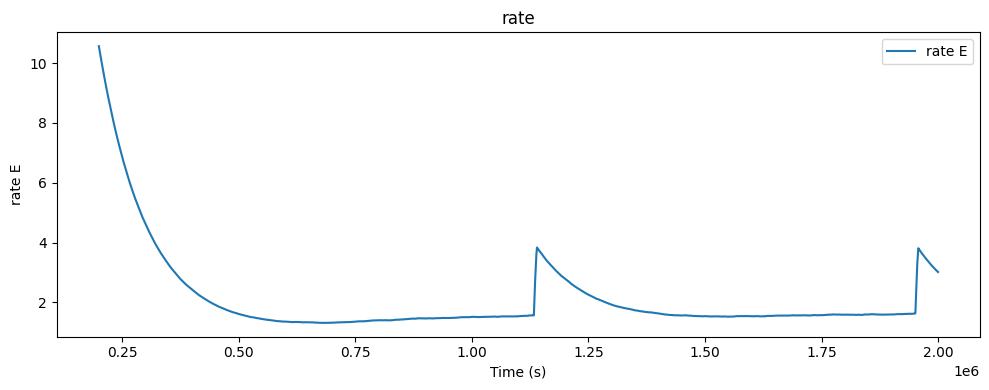

In [31]:
r_est_E = net['rate_pop_mon_E']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[1000:]/ms, r_est_E.r_pop_E[0,1000:]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

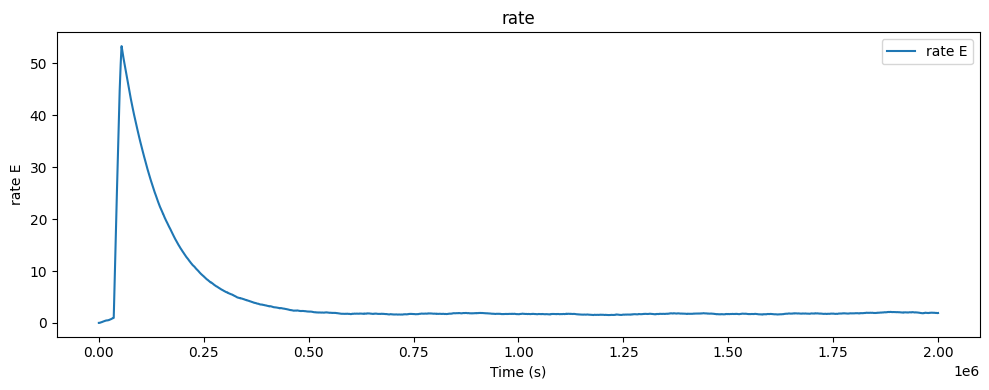

In [32]:
r_est_E = net['r_est']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t/ms, r_est_E.r_est[0]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

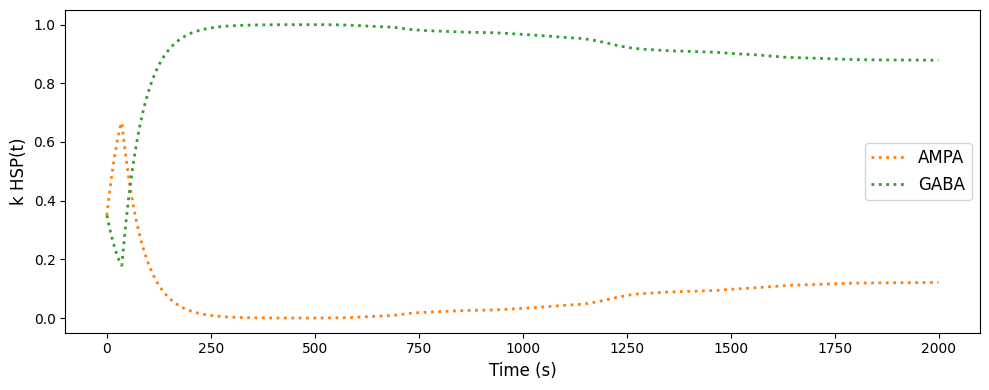

In [33]:
kAMPA_mon_E=net['k_AMPA_E_hsp']
kGABA_mon_E=net['k_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(kAMPA_mon_E.t/second, kAMPA_mon_E.k_AMPA_E_hsp[45], label='AMPA',color='tab:orange',linestyle=':',linewidth=2)
plt.plot(kGABA_mon_E.t/second, kGABA_mon_E.k_GABA_E_hsp[45], label='GABA',color='tab:green',linestyle=':',linewidth=2)
plt.xlabel('Time (s)',fontsize=12)
plt.ylabel('k HSP(t)',fontsize=12)
#plt.title('Homeostatic Synaptic Scaling')
plt.legend(loc=5,fontsize=12)
plt.tight_layout()

In [34]:
net.store('baseline')

In [35]:
def hsp_sigmoid(x):
    return 1.0 / (1.0 + np.exp(-15.0 * x))

def hsp_func(rate_hz, kE, kI,
            target_hz=2.0,
            tau_ins_AMPA_s=500.0,
            tau_int_AMPA_s=500.0,
            tau_ins_GABA_s=500.0,
            tau_int_GABA_s=500.0):

    x_up = (target_hz - rate_hz) / target_hz - 0.5
    x_down = (rate_hz - target_hz) / target_hz - 0.5

    s_up = hsp_sigmoid(x_up)
    s_down = hsp_sigmoid(x_down)

    dkE = (1.0 - kE) * s_up / tau_ins_AMPA_s - kE * s_down / tau_int_AMPA_s
    dkI = -kI * s_up / tau_int_GABA_s + (1.0 - kI) * s_down / tau_ins_GABA_s

    return dkE, dkI


In [ ]:
def eval_phase_point(net, kE, kI, alpha=1.0, run_time=1000*second,analysis_start_s=2000*second):
    net.restore('baseline')

    P_E = net['P_E']
    C_PG_E = net['PG_E']
    P_I = net['P_I']

    #rate_mon_E = net['rate_pop_mon_E']
    rate_mon_E = net['r_est']  

    P_E.k_AMPA_E_hsp = kE
    P_E.k_GABA_E_hsp = kI
    P_E.x_spike = 0 

    # HSP inf
    P_E.tau_ins_AMPA_E = 1e30 * second
    P_E.tau_int_AMPA_E = 1e30 * second
    P_E.tau_ins_GABA_E = 1e30 * second
    P_E.tau_int_GABA_E = 1e30 * second

    #scotoma/small undercut
    baseline_w = float(C_PG_E.w[0])
    C_PG_E.w[:] = alpha * baseline_w

    net.run(run_time, report='text')
    t=rate_mon_E.t
    mask = t >= analysis_start_s
    #r_trace_hz = np.array(rate_mon_E.r_pop_E[0,-500:] / Hz)
    r_trace_hz = np.array(rate_mon_E.r_est[0,mask] / Hz) #,-500:
    max_rate_hz = np.max(r_trace_hz)
    mean_rate_hz = np.mean(r_trace_hz)

    return max_rate_hz, mean_rate_hz, r_trace_hz

In [ ]:
def run_full_hsp_trajectory(net, alpha=1.0, run_time=3000*second,
                            analysis_start_s=2000.0, tau_ins_AMPA=500*second,tau_int_AMPA=500*second,
                            tau_ins_GABA=500*second,tau_int_GABA=500*second):

    net.restore('baseline')

    P_E = net['P_E']
    PG_E = net['PG_E']
    rate_mon_E = net['rate_pop_mon_E']
    rate_mon_E_45 = net['r_est']
    gAMPA_mon_E = net['k_AMPA_E_hsp']
    gGABA_mon_E = net['k_GABA_E_hsp']

    baseline_w = float(PG_E.w[0])
    PG_E.w[:] = alpha * baseline_w
    P_E.tau_ins_AMPA_E = tau_ins_AMPA
    P_E.tau_int_AMPA_E = tau_int_AMPA
    P_E.tau_ins_GABA_E = tau_ins_GABA
    P_E.tau_int_GABA_E = tau_int_GABA

    # do NOT freeze HSP here
    net.run(run_time, report='text')

    t = np.array(rate_mon_E.t / second)
    mask = t >= analysis_start_s

    return {
        't': t[mask],
        'r_trace_hz': np.array(rate_mon_E.r_pop_E[0, mask] / Hz),
        'r_trace_hz_45': np.array(rate_mon_E_45.r_est[0] / Hz),
        'kE_trace': np.array(gAMPA_mon_E.k_AMPA_E_hsp[45, mask]),
        'kI_trace': np.array(gGABA_mon_E.k_GABA_E_hsp[45, mask]),
    }

In [ ]:
kE_vals = np.linspace(0.0, 1.0, 11)
kI_vals = np.linspace(0.0, 1.0, 11)

max_rate_map = np.zeros((len(kI_vals), len(kE_vals)))
mean_rate_map = np.zeros((len(kI_vals), len(kE_vals)))
dkE_map = np.zeros((len(kI_vals), len(kE_vals)))
dkI_map = np.zeros((len(kI_vals), len(kE_vals)))

alpha = 0.90   

for i, kI in enumerate(kI_vals):
    for j, kE in enumerate(kE_vals):

        max_r, mean_r, r_trace = eval_phase_point(
            net,
            kE=kE,
            kI=kI,
            alpha=alpha,
            run_time=1000*second
        )

        max_rate_map[i, j] = max_r
        mean_rate_map[i, j] = mean_r

        dkE, dkI = hsp_func(
            rate_hz=mean_r,   
            kE=kE,
            kI=kI,
            target_hz=2.0,
            tau_ins_AMPA_s=100.0,
            tau_int_AMPA_s=50.0,
            tau_ins_GABA_s=100.0,
            tau_int_GABA_s=50.0
        )

        dkE_map[i, j] = dkE
        dkI_map[i, j] = dkI

In [24]:
res_trace=run_full_hsp_trajectory(net,alpha=0.90,run_time=2000*second,analysis_start_s=1000.0, tau_ins_AMPA=100.0*second,
            tau_int_AMPA=50.0*second,
            tau_ins_GABA=100.0*second,
            tau_int_GABA=50.0*second)
kE_trace=res_trace['kE_trace']
kI_trace=res_trace['kI_trace']
t=res_trace['t']

Starting simulation at t=2. ks for a duration of 2. ks
127.62 s (6%) simulated in 10s, estimated 2m 27s remaining.
243.22 s (12%) simulated in 20s, estimated 2m 24s remaining.
0.36835 ks (18%) simulated in 30s, estimated 2m 13s remaining.
0.489614 ks (24%) simulated in 40s, estimated 2m 3s remaining.
0.594879 ks (29%) simulated in 50s, estimated 1m 58s remaining.
0.711665 ks (35%) simulated in 1m 0s, estimated 1m 49s remaining.
0.83471 ks (41%) simulated in 1m 10s, estimated 1m 38s remaining.
0.964074 ks (48%) simulated in 1m 21s, estimated 1m 27s remaining.
1.089727 ks (54%) simulated in 1m 31s, estimated 1m 16s remaining.
1.215782 ks (60%) simulated in 1m 41s, estimated 1m 5s remaining.
1.337666 ks (66%) simulated in 1m 51s, estimated 55s remaining.
1.435825 ks (71%) simulated in 2m 1s, estimated 48s remaining.
1.556816 ks (77%) simulated in 2m 11s, estimated 37s remaining.
1.678624 ks (83%) simulated in 2m 21s, estimated 27s remaining.
1.793706 ks (89%) simulated in 2m 31s, estimate

In [ ]:
dt = np.diff(t)
dKe_fd = np.diff(kE_trace) / dt
dKi_fd = np.diff(kI_trace) / dt

In [ ]:
dKe_rhs[n], dKi_rhs[n] = hsp_func(
    rE_hz = r_est_trace[n],
    Ke    = kE_trace[n],
    Ki    = kI_trace[n],
    target_hz=2.0,
    tau_ins_AMPA_s=500.0,
    tau_int_AMPA_s=500.0,
    tau_ins_GABA_s=500.0,
    tau_int_GABA_s=500.0
)

In [ ]:
plt.plot(kE_trace, kI_trace, 'k-')

plt.quiver(
    kE_trace[::10],
    kI_trace[::10],
    dKe_rhs[::10],
    dKi_rhs[::10],
    color='red'
)

# chat gpt

In [36]:
def run_full_hsp_trajectory(net, alpha=1.0, run_time=2000*second,
                            analysis_start_s=2000.0,
                            tau_ins_AMPA=100*second,
                            tau_int_AMPA=50*second,
                            tau_ins_GABA=100*second,
                            tau_int_GABA=50*second,
                            neuron_idx=45):

    net.restore('baseline')

    P_E = net['P_E']
    PG_E = net['PG_E']

    gAMPA_mon_E = net['k_AMPA_E_hsp']
    gGABA_mon_E = net['k_GABA_E_hsp']
    r_est_mon = net['r_est']   # StateMonitor on neuron 45 in your build_network

    baseline_w = float(PG_E.w[0])
    PG_E.w[:] = alpha * baseline_w

    P_E.tau_ins_AMPA_E = tau_ins_AMPA
    P_E.tau_int_AMPA_E = tau_int_AMPA
    P_E.tau_ins_GABA_E = tau_ins_GABA
    P_E.tau_int_GABA_E = tau_int_GABA

    net.run(run_time, report='text')

    # Use the SAME monitor timebase as r_est_mon
    t_all = np.array(r_est_mon.t / second)
    mask = t_all >= analysis_start_s

    return {
        't': t_all[mask],
        'r_est_trace': np.array(r_est_mon.r_est[0, mask] / Hz),   # neuron 45
        'kE_trace': np.array(gAMPA_mon_E.k_AMPA_E_hsp[neuron_idx, mask]),
        'kI_trace': np.array(gGABA_mon_E.k_GABA_E_hsp[neuron_idx, mask]),
    }

In [37]:
def rhs_along_trajectory(t, r_est_trace, kE_trace, kI_trace,
                         target_hz=2.0,
                         tau_ins_AMPA_s=100.0,
                         tau_int_AMPA_s=50.0,
                         tau_ins_GABA_s=100.0,
                         tau_int_GABA_s=50.0):
    n = len(t)
    dkE_rhs = np.zeros(n)
    dkI_rhs = np.zeros(n)

    for i in range(n):
        dkE_rhs[i], dkI_rhs[i] = hsp_func(
            rate_hz=r_est_trace[i],
            kE=kE_trace[i],
            kI=kI_trace[i],
            target_hz=target_hz,
            tau_ins_AMPA_s=tau_ins_AMPA_s,
            tau_int_AMPA_s=tau_int_AMPA_s,
            tau_ins_GABA_s=tau_ins_GABA_s,
            tau_int_GABA_s=tau_int_GABA_s
        )

    return dkE_rhs, dkI_rhs

In [38]:
def finite_difference_motion(t, kE_trace, kI_trace):
    dt = np.diff(t)
    dkE_fd = np.diff(kE_trace) / dt
    dkI_fd = np.diff(kI_trace) / dt
    t_mid = 0.5 * (t[:-1] + t[1:])
    kE_mid = 0.5 * (kE_trace[:-1] + kE_trace[1:])
    kI_mid = 0.5 * (kI_trace[:-1] + kI_trace[1:])
    return t_mid, kE_mid, kI_mid, dkE_fd, dkI_fd

In [39]:
res_trace = run_full_hsp_trajectory(
    net,
    alpha=0.90,
    run_time=2000*second,
    analysis_start_s=2000.0,
    tau_ins_AMPA=100.0*second,
    tau_int_AMPA=50.0*second,
    tau_ins_GABA=100.0*second,
    tau_int_GABA=50.0*second,
    neuron_idx=45
)

t = res_trace['t']
r_est_trace = res_trace['r_est_trace']
kE_trace = res_trace['kE_trace']
kI_trace = res_trace['kI_trace']

dkE_rhs, dkI_rhs = rhs_along_trajectory(
    t, r_est_trace, kE_trace, kI_trace,
    target_hz=2.0,
    tau_ins_AMPA_s=100.0,
    tau_int_AMPA_s=50.0,
    tau_ins_GABA_s=100.0,
    tau_int_GABA_s=50.0
)

t_mid, kE_mid, kI_mid, dkE_fd, dkI_fd = finite_difference_motion(
    t, kE_trace, kI_trace
)

Starting simulation at t=2. ks for a duration of 2. ks
135.333 s (6%) simulated in 10s, estimated 2m 27s remaining.
277.265 s (13%) simulated in 20s, estimated 2m 8s remaining.
0.419928 ks (20%) simulated in 30s, estimated 1m 55s remaining.
0.555569 ks (27%) simulated in 40s, estimated 1m 46s remaining.
0.671506 ks (33%) simulated in 50s, estimated 1m 40s remaining.
0.809824 ks (40%) simulated in 1m 0s, estimated 1m 29s remaining.
0.964544 ks (48%) simulated in 1m 10s, estimated 1m 16s remaining.
1.086706 ks (54%) simulated in 1m 20s, estimated 1m 8s remaining.
1.223535 ks (61%) simulated in 1m 30s, estimated 58s remaining.
1.360682 ks (68%) simulated in 1m 40s, estimated 47s remaining.
1.479068 ks (73%) simulated in 1m 50s, estimated 39s remaining.
1.61679 ks (80%) simulated in 2m 0s, estimated 29s remaining.
1.764567 ks (88%) simulated in 2m 10s, estimated 17s remaining.
1.900074 ks (95%) simulated in 2m 20s, estimated 7s remaining.
2. ks (100%) simulated in 2m 29s


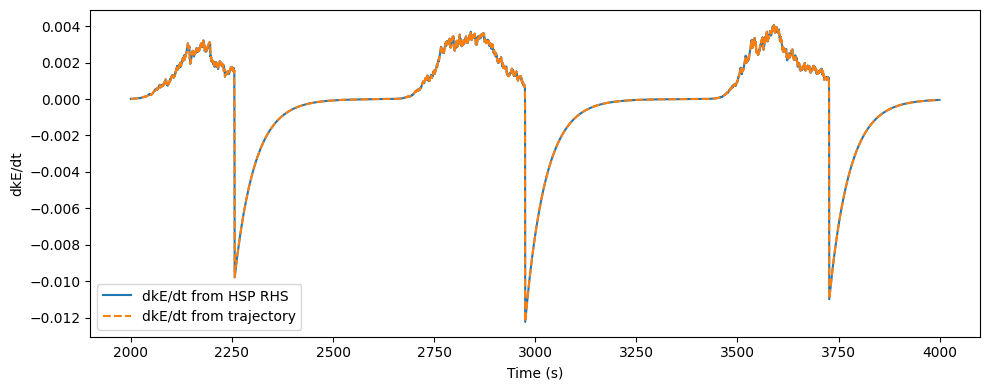

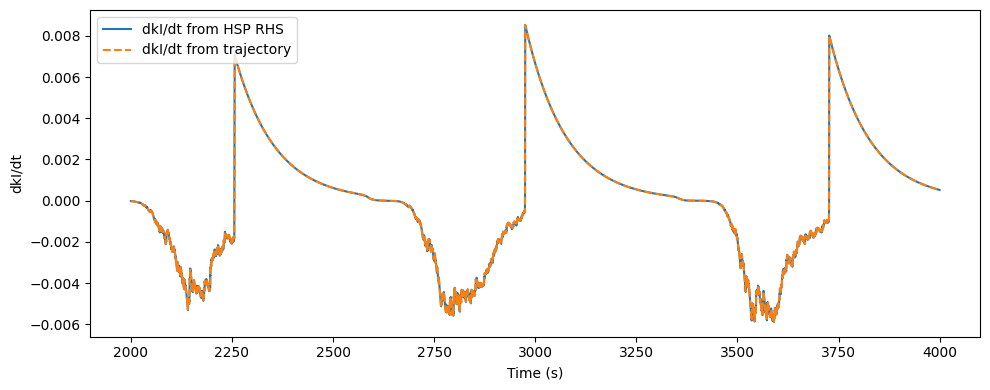

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.plot(t, dkE_rhs, label='dkE/dt from HSP RHS')
plt.plot(t_mid, dkE_fd, '--', label='dkE/dt from trajectory')
plt.xlabel('Time (s)')
plt.ylabel('dkE/dt')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(t, dkI_rhs, label='dkI/dt from HSP RHS')
plt.plot(t_mid, dkI_fd, '--', label='dkI/dt from trajectory')
plt.xlabel('Time (s)')
plt.ylabel('dkI/dt')
plt.legend()
plt.tight_layout()
plt.show()

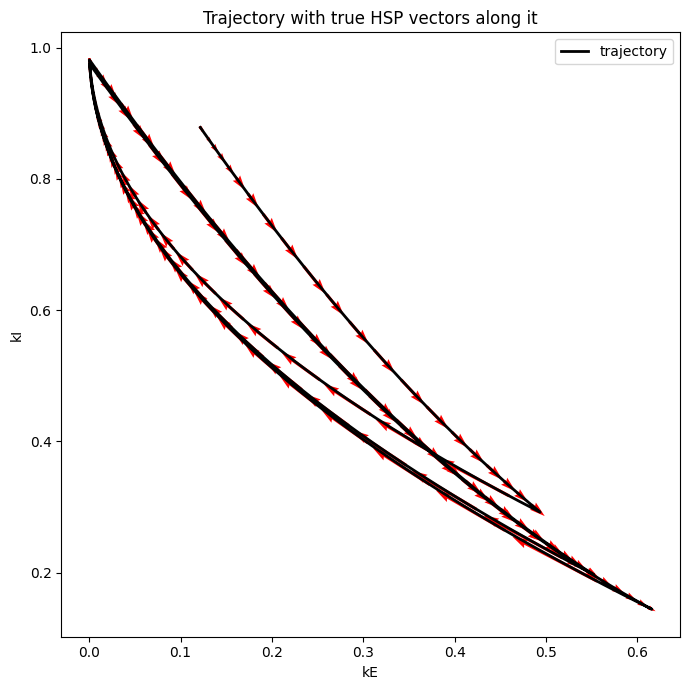

In [45]:
step = 50  # thin arrows for readability
mag = np.sqrt(dkE_rhs**2 + dkI_rhs**2) + 1e-12

u = dkE_rhs / mag
v = dkI_rhs / mag
plt.figure(figsize=(7,7))
plt.plot(kE_trace, kI_trace, 'k-', linewidth=2, label='trajectory')

plt.quiver(
    kE_trace[::step],
    kI_trace[::step],
    dkE_rhs[::step],
    dkI_rhs[::step],
    color='red',
    angles='xy',
    scale_units='xy',
    scale=0.12,   
    width=0.005
)

plt.xlabel('kE')
plt.ylabel('kI')
plt.title('Trajectory with true HSP vectors along it')
plt.legend()
plt.tight_layout()
plt.show()